In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import streamlit as st

In [2]:
df = pd.read_csv(r'D:\project python\Coffee Shop Sales Dataset\Coffee Shop Sales.csv')

In [3]:
df

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,1/1/23,7:06:11,2,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,1/1/23,7:08:56,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,1/1/23,7:14:04,2,5,Lower Manhattan,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,1/1/23,7:20:24,1,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,1/1/23,7:22:41,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
...,...,...,...,...,...,...,...,...,...,...,...
149111,149452,6/30/23,20:18:41,2,8,Hell's Kitchen,44,2.50,Tea,Brewed herbal tea,Peppermint Rg
149112,149453,6/30/23,20:25:10,2,8,Hell's Kitchen,49,3.00,Tea,Brewed Black tea,English Breakfast Lg
149113,149454,6/30/23,20:31:34,1,8,Hell's Kitchen,45,3.00,Tea,Brewed herbal tea,Peppermint Lg
149114,149455,6/30/23,20:57:19,1,8,Hell's Kitchen,40,3.75,Coffee,Barista Espresso,Cappuccino


# CLEAN STEPS

### (1) Check Data Types

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   transaction_date  149116 non-null  object 
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  object 
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  object 
 9   product_type      149116 non-null  object 
 10  product_detail    149116 non-null  object 
dtypes: float64(1), int64(4), object(6)
memory usage: 12.5+ MB


#### N.B : change type [transaction_date,transaction_time] from object to datetime

In [5]:
df['transaction_date'] = pd.to_datetime(
    df['transaction_date']
)

C:\Users\moh\AppData\Local\Temp\ipykernel_6872\2479447616.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['transaction_date'] = pd.to_datetime(


In [6]:
df['transaction_time'] = pd.to_datetime(
    df['transaction_time'],
    format='%H:%M:%S'
).dt.time

In [7]:
df['datetime'] = pd.to_datetime(
    df['transaction_date'].astype(str)
    + ' '
    + df['transaction_time'].astype(str)
)

In [8]:
df['datetime']

0        2023-01-01 07:06:11
1        2023-01-01 07:08:56
2        2023-01-01 07:14:04
3        2023-01-01 07:20:24
4        2023-01-01 07:22:41
                 ...        
149111   2023-06-30 20:18:41
149112   2023-06-30 20:25:10
149113   2023-06-30 20:31:34
149114   2023-06-30 20:57:19
149115   2023-06-30 20:57:19
Name: datetime, Length: 149116, dtype: datetime64[ns]

### (2) Check Missing Value

In [9]:
df.isna().sum()

transaction_id      0
transaction_date    0
transaction_time    0
transaction_qty     0
store_id            0
store_location      0
product_id          0
unit_price          0
product_category    0
product_type        0
product_detail      0
datetime            0
dtype: int64

### (3) Check Duplicate

In [10]:
df.duplicated().sum()

np.int64(0)

### (4) Check Outliers

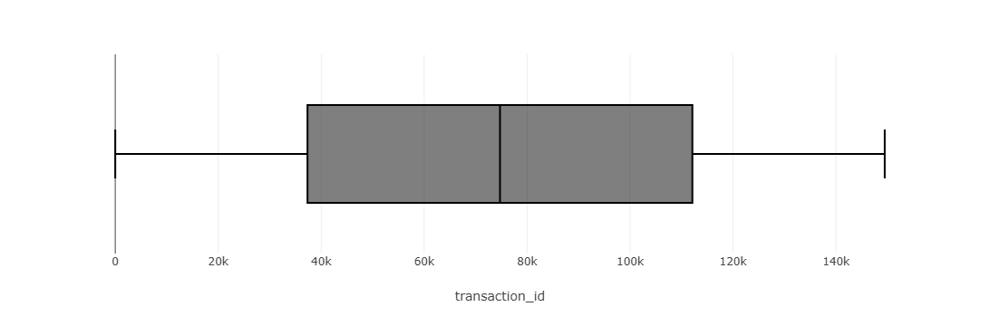

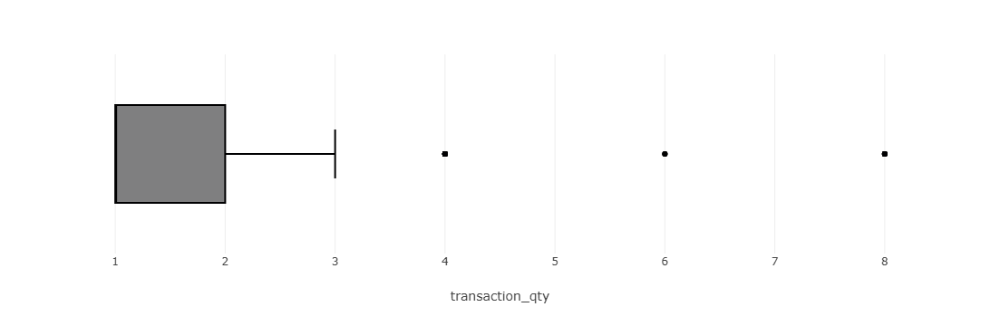

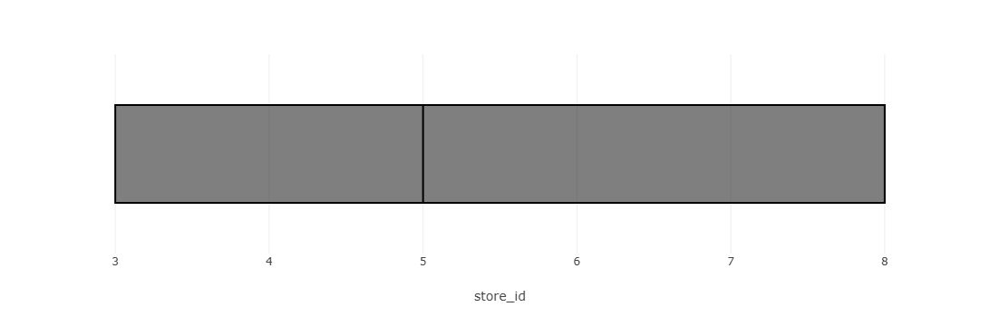

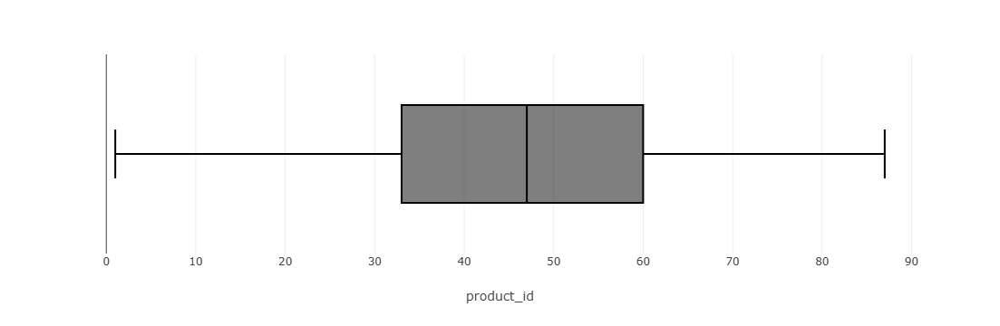

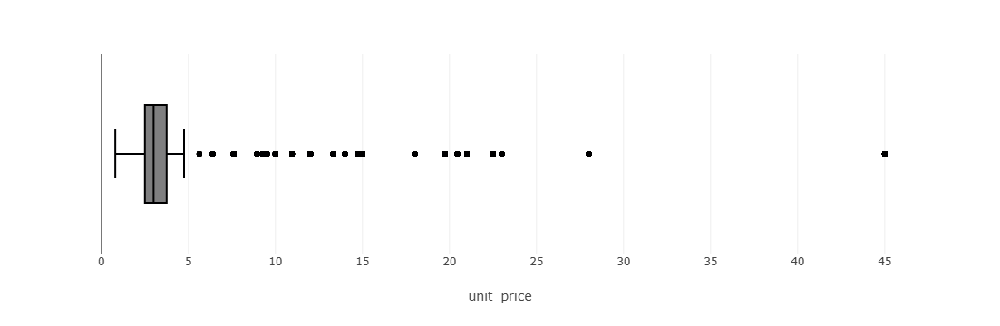

In [11]:
for col in df.select_dtypes(include = 'number').columns:
    fig = px.box(df, x= col)
    fig.show()

### (4) Check Consistant values

In [12]:
df.describe(include = 'object')

,transaction_time,store_location,product_category,product_type,product_detail
count,149116,149116,149116,149116,149116
unique,25762,3,9,29,80
top,09:31:15,Hell's Kitchen,Coffee,Brewed Chai tea,Chocolate Croissant
freq,41,50735,58416,17183,3076


In [13]:
df.describe().round(2)

,transaction_id,transaction_date,transaction_qty,store_id,product_id,unit_price,datetime
count,149116.00,149116,149116.00,149116.00,149116.00,149116.00,149116
mean,74737.37,2023-04-15 11:50:32.173609984,1.44,5.34,47.92,3.38,2023-04-16 00:04:47.989404160
min,1.00,2023-01-01 00:00:00,1.00,3.00,1.00,0.80,2023-01-01 07:06:11
25%,37335.75,2023-03-06 00:00:00,1.00,3.00,33.00,2.50,2023-03-06 13:37:08
50%,74727.50,2023-04-24 00:00:00,1.00,5.00,47.00,3.00,2023-04-24 08:24:32.500000
75%,112094.25,2023-05-30 00:00:00,2.00,8.00,60.00,3.75,2023-05-30 07:16:13
max,149456.00,2023-06-30 00:00:00,8.00,8.00,87.00,45.00,2023-06-30 20:57:19
std,43153.60,NaN,0.54,2.07,17.93,2.66,NaN


### (4) Check Unique values

In [14]:
df.nunique()

transaction_id      149116
transaction_date       181
transaction_time     25762
transaction_qty          6
store_id                 3
store_location           3
product_id              80
unit_price              41
product_category         9
product_type            29
product_detail          80
datetime            116129
dtype: int64

#### N.B : ALL results ---- accept

In [15]:
df['hours']=df['datetime'].dt.hour

In [16]:
df['month']=df['datetime'].dt.month

In [17]:
df['month_name'] = df['transaction_date'].dt.month_name()

In [18]:
df['day']=df['datetime'].dt.day

In [19]:
df['dayname']=df['datetime'].dt.day_name()

In [20]:
df

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail,datetime,hours,month,month_name,day,dayname
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.00,Coffee,Gourmet brewed coffee,Ethiopia Rg,2023-01-01 07:06:11,7,1,January,1,Sunday
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,2023-01-01 07:08:56,7,1,January,1,Sunday
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg,2023-01-01 07:14:04,7,1,January,1,Sunday
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.00,Coffee,Drip coffee,Our Old Time Diner Blend Sm,2023-01-01 07:20:24,7,1,January,1,Sunday
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.10,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg,2023-01-01 07:22:41,7,1,January,1,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149111,149452,2023-06-30,20:18:41,2,8,Hell's Kitchen,44,2.50,Tea,Brewed herbal tea,Peppermint Rg,2023-06-30 20:18:41,20,6,June,30,Friday
149112,149453,2023-06-30,20:25:10,2,8,Hell's Kitchen,49,3.00,Tea,Brewed Black tea,English Breakfast Lg,2023-06-30 20:25:10,20,6,June,30,Friday
149113,149454,2023-06-30,20:31:34,1,8,Hell's Kitchen,45,3.00,Tea,Brewed herbal tea,Peppermint Lg,2023-06-30 20:31:34,20,6,June,30,Friday
149114,149455,2023-06-30,20:57:19,1,8,Hell's Kitchen,40,3.75,Coffee,Barista Espresso,Cappuccino,2023-06-30 20:57:19,20,6,June,30,Friday


In [21]:
#create Revenue
df['Revenue'] = df['transaction_qty'] * df['unit_price']

### Business KPIs:

In [22]:
# account Total Sales Value(Total_Revenue):
Total_Revenue = df['Revenue'] .sum().round(2)
print(Total_Revenue)

698812.33


In [23]:
# account Total_Quantity: 
Total_Sales_Units = df['transaction_qty'].sum()
print(Total_Sales_Units)

214470


In [24]:
# account Total Transactions:
Total_Trans = df['transaction_id'].nunique()
print(Total_Trans)

149116


In [25]:
# Average Order Value:
Avg_order_value = df['Revenue'].mean().round(2)
print(Avg_order_value)

4.69


In [26]:
# Best Stores
Store_Sales = df.groupby('store_location')['Revenue'].sum().sort_values(ascending = False)
Store_Sales

store_location
Hell's Kitchen     236511.17
Astoria            232243.91
Lower Manhattan    230057.25
Name: Revenue, dtype: float64

In [27]:
# Best Product
Prod_Cat_Sales = df.groupby('product_category')['Revenue'].sum().sort_values(ascending = False)
Prod_Cat_Sales

product_category
Coffee                269952.45
Tea                   196405.95
Bakery                 82315.64
Drinking Chocolate     72416.00
Coffee beans           40085.25
Branded                13607.00
Loose Tea              11213.60
Flavours                8408.80
Packaged Chocolate      4407.64
Name: Revenue, dtype: float64

In [28]:
# Best Product Type
Prod_Type_Sales = df.groupby('product_type')['Revenue'].sum().sort_values(ascending = False)
Prod_Type_Sales

product_type
Barista Espresso         91406.20
Brewed Chai tea          77081.95
Hot chocolate            72416.00
Gourmet brewed coffee    70034.60
Brewed Black tea         47932.00
Brewed herbal tea        47539.50
Premium brewed coffee    38781.15
Organic brewed coffee    37746.50
Scone                    36866.12
Drip coffee              31984.00
Pastry                   25655.99
Brewed Green tea         23852.50
Biscotti                 19793.53
Premium Beans            14583.50
Organic Beans             8509.50
Housewares                7444.00
Gourmet Beans             6798.00
Clothing                  6163.00
Regular syrup             6084.80
Espresso Beans            5560.25
Chai tea                  4301.25
House blend Beans         3294.00
Herbal tea                2729.75
Drinking Chocolate        2728.04
Black tea                 2711.85
Sugar free syrup          2324.00
Organic Chocolate         1679.60
Green tea                 1470.75
Green beans               1340.00
N

In [29]:
# Best Hour & Day & Month
Prod_Type_Sales = df.groupby(['hours','day','month'])['Revenue'].sum().sort_values(ascending = False)
Prod_Type_Sales

hours  day  month
10     17   6        1211.25
9      14   6        1187.25
            5        1185.50
8      14   6        1180.70
       20   5        1158.70
                      ...   
20     30   3          11.85
       31   3           8.50
       27   1           8.35
       9    4           7.15
            1           6.00
Name: Revenue, Length: 2512, dtype: float64

In [30]:
# Best Hour
Best_Hour_Sales = df.groupby('hours')['Revenue'].sum().sort_values(ascending = False)
Best_Hour_Sales

hours
10    88673.39
9     85169.53
8     82699.87
7     63526.47
11    46319.14
15    41733.10
14    41304.74
16    41122.75
13    40367.45
12    40192.79
17    40134.31
18    34286.20
19    28446.68
6     21900.27
20     2935.64
Name: Revenue, dtype: float64

In [31]:
# Best Day
Best_Day_Sales = df.groupby('day')['Revenue'].sum().sort_values(ascending = False)
Best_Day_Sales

day
19    25853.41
27    25538.35
13    25322.15
16    25292.55
8     25253.08
18    24973.43
24    24958.85
26    24866.91
15    24746.80
17    24636.00
23    24306.55
25    24291.75
21    24260.75
10    24132.21
9     23804.22
22    23697.98
14    23689.52
20    23688.36
11    22415.67
12    22360.04
3     21797.80
1     21673.10
2     21164.15
7     20966.30
5     20833.70
4     20455.85
28    19582.10
30    19278.36
6     19149.55
29    15916.50
31     9906.34
Name: Revenue, dtype: float64

In [32]:
# Best Month
Best_Month_Sales = df.groupby('month')['Revenue'].sum().sort_values(ascending = False)
Best_Month_Sales

month
6    166485.88
5    156727.76
4    118941.08
3     98834.68
1     81677.74
2     76145.19
Name: Revenue, dtype: float64

In [33]:
# top 10 products
Top_Prod_Sales = df.groupby('product_detail')['Revenue'].sum().sort_values(ascending = False).head(10)
Top_Prod_Sales

product_detail
Sustainably Grown Organic Lg    21151.75
Dark chocolate Lg               21006.00
Latte Rg                        19112.25
Cappuccino Lg                   17641.75
Morning Sunrise Chai Lg         17384.00
Latte                           17257.50
Jamaican Coffee River Lg        16481.25
Sustainably Grown Organic Rg    16233.75
Cappuccino                      15997.50
Brazilian Lg                    15109.50
Name: Revenue, dtype: float64

## Univariate Analysis:

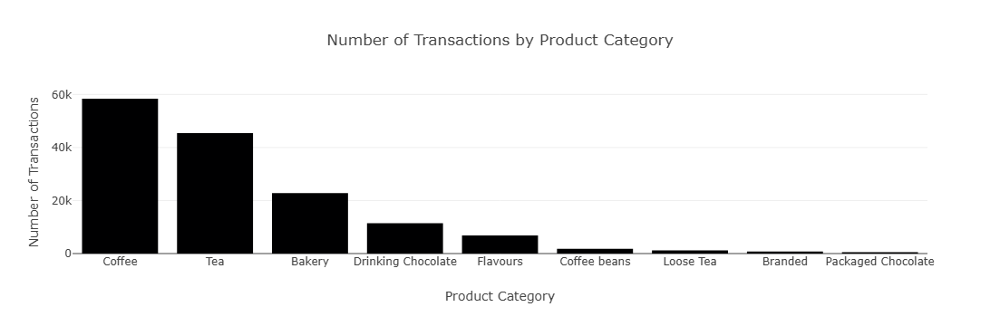

In [34]:
category_count = df["product_category"].value_counts().reset_index()

fig = px.bar(
    category_count,
    x="product_category",
    y="count",
    title="Number of Transactions by Product Category",
    labels={
        "product_category": "Product Category",
        "count": "Number of Transactions"
    }
)

fig.show()

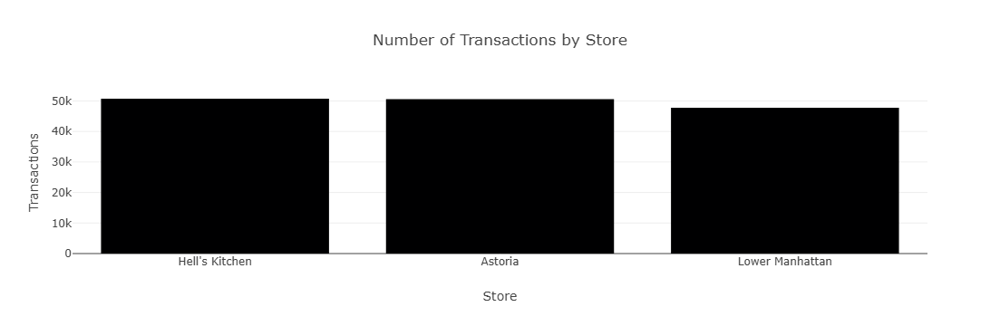

In [35]:
store_count = df["store_location"].value_counts().reset_index()

fig = px.bar(
    store_count,
    x="store_location",
    y="count",
    title="Number of Transactions by Store",
    labels={
        "store_location": "Store",
        "count": "Transactions"
    }
)

fig.show()

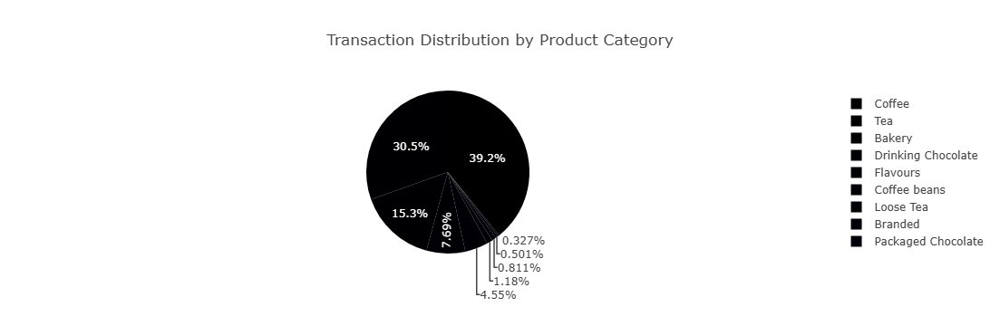

In [36]:
category_count = df["product_category"].value_counts().reset_index()

fig = px.pie(
    category_count,
    names="product_category",
    values="count",
    title="Transaction Distribution by Product Category"
)

fig.show()

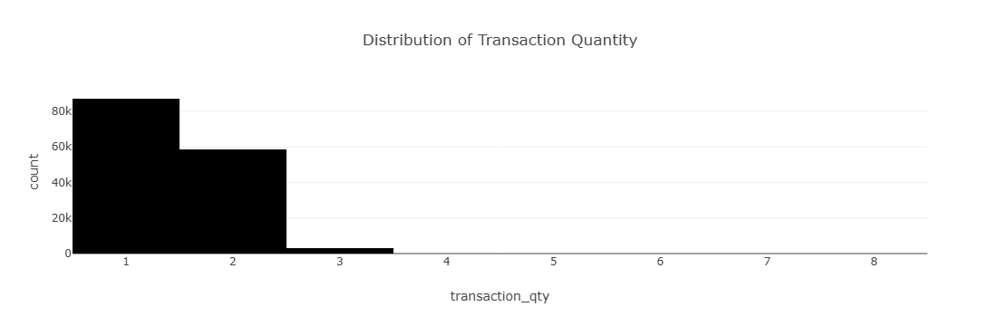

In [37]:
fig = px.histogram(
    df,
    x="transaction_qty",
    title="Distribution of Transaction Quantity",
    nbins=10
)

fig.show()

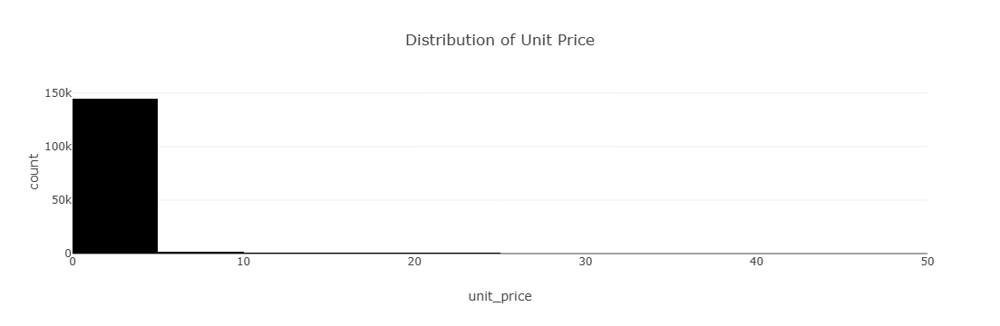

In [38]:
fig = px.histogram(
    df,
    x="unit_price",
    title="Distribution of Unit Price",
    nbins=20
)

fig.show()

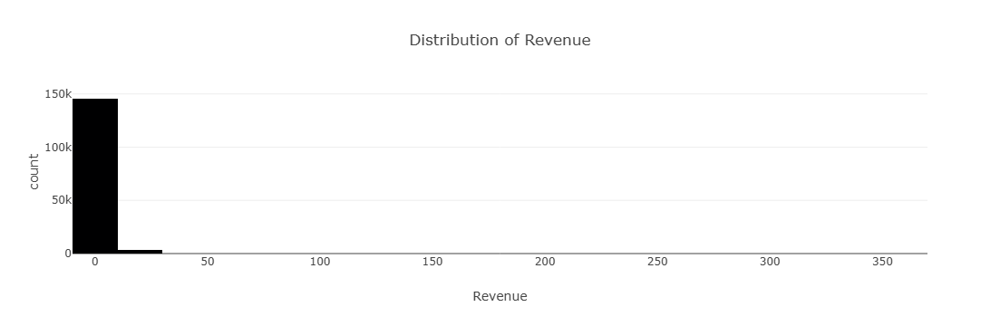

In [39]:
fig = px.histogram(
    df,
    x="Revenue",
    title="Distribution of Revenue",
    nbins=30
)

fig.show()

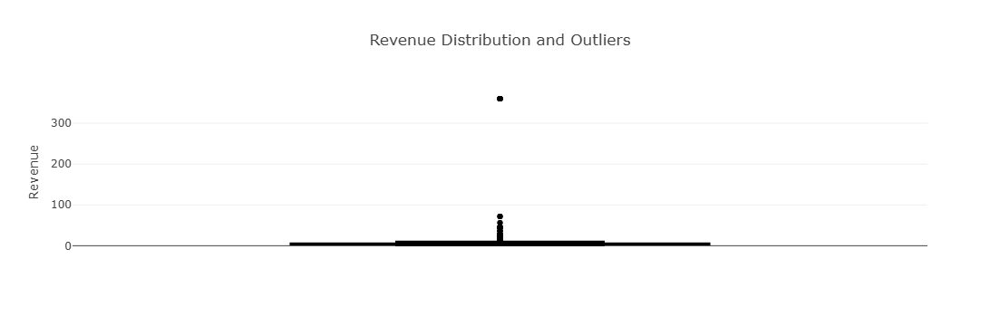

In [40]:
fig = px.box(
    df,
    y="Revenue",
    title="Revenue Distribution and Outliers"
)

fig.show()

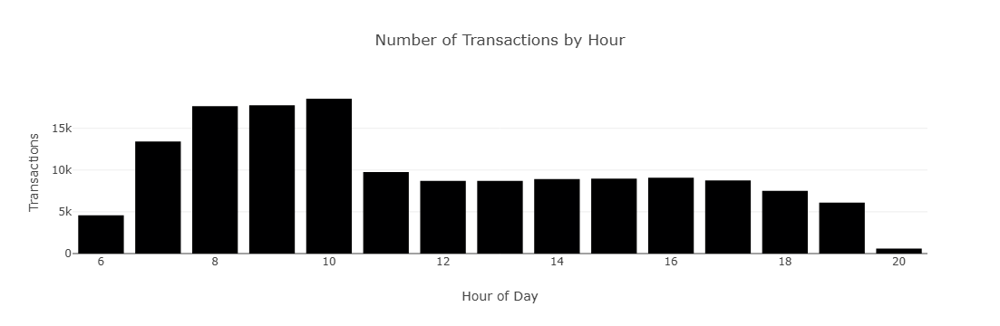

In [41]:
hour_count = df["hours"].value_counts().sort_index().reset_index()

fig = px.bar(
    hour_count,
    x="hours",
    y="count",
    title="Number of Transactions by Hour",
    labels={
        "hours": "Hour of Day",
        "count": "Transactions"
    }
)

fig.show()

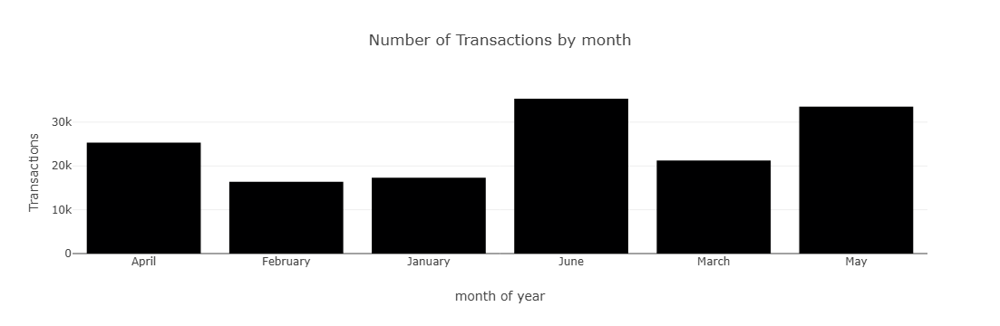

In [42]:
month_count = df["month_name"].value_counts().sort_index().reset_index()

fig = px.bar(
    month_count,
    x="month_name",
    y="count",
    title="Number of Transactions by month",
    labels={
        "month_name": "month of year",
        "count": "Transactions"
    }
)

fig.show()

## Bivariate Analysis

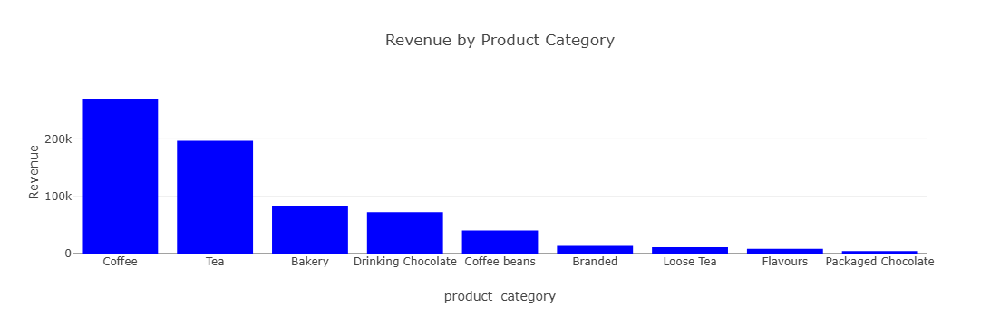

In [43]:
category_sales = (
    df.groupby("product_category", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
)

fig1 = px.bar(
    category_sales,
    x="product_category",
    y="Revenue",
    title="Revenue by Product Category",color_discrete_sequence=['blue']
)

fig1.show()

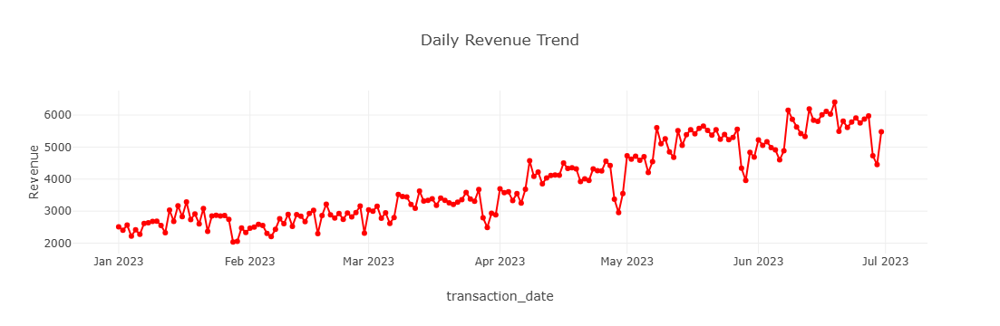

In [44]:
daily_sales = (
    df.groupby("transaction_date", as_index=False)["Revenue"]
    .sum()
)

fig2 = px.line(
    daily_sales,
    x="transaction_date",
    y="Revenue",
    title="Daily Revenue Trend",
    markers=True,color_discrete_sequence=['red']
)

fig2.show()

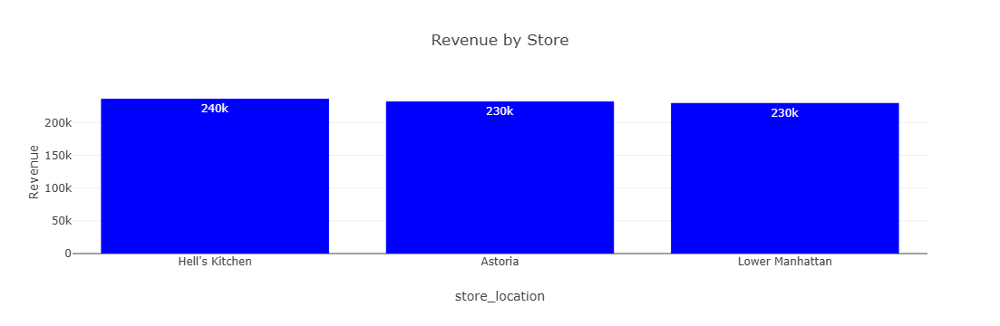

In [45]:
store_sales = (
    df.groupby("store_location", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
)

fig3 = px.bar(
    store_sales,
    x="store_location",
    y="Revenue",
    title="Revenue by Store",
    text_auto=".2s",color_discrete_sequence=['blue']
)

fig3.show()

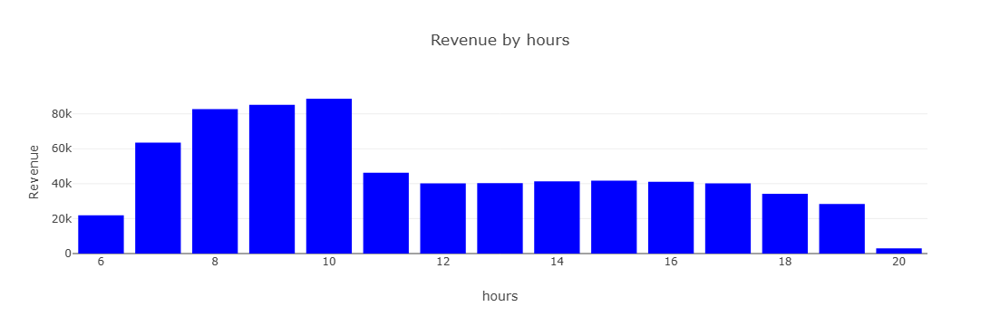

In [46]:
hourly_sales = (
    df.groupby("hours", as_index=False)["Revenue"]
    .sum()
)

fig4 = px.bar(
    hourly_sales,
    x="hours",
    y="Revenue",
    title="Revenue by hours",color_discrete_sequence=['blue']
)

fig4.show()

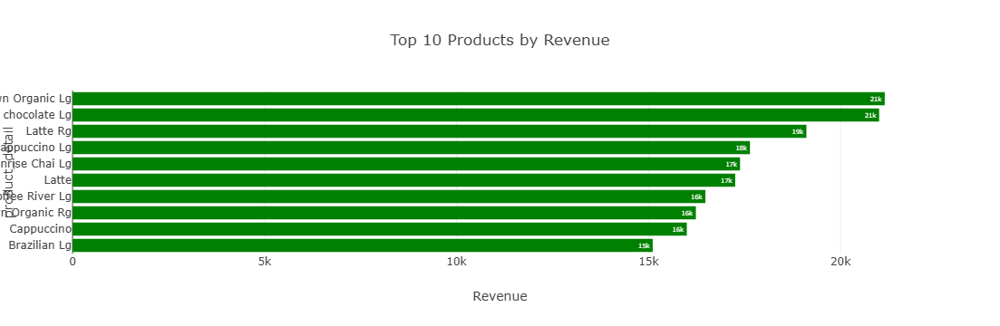

In [47]:
top_products = (
    df.groupby("product_detail", as_index=False)["Revenue"]
    .sum()
    .sort_values("Revenue", ascending=False)
    .head(10)
)

fig5 = px.bar(
    top_products.sort_values("Revenue"),
    x="Revenue",
    y="product_detail",
    orientation="h",
    title="Top 10 Products by Revenue",b
    text_auto=".2s",color_discrete_sequence=['green']
)

fig5.show()

## Multivariate Analysis

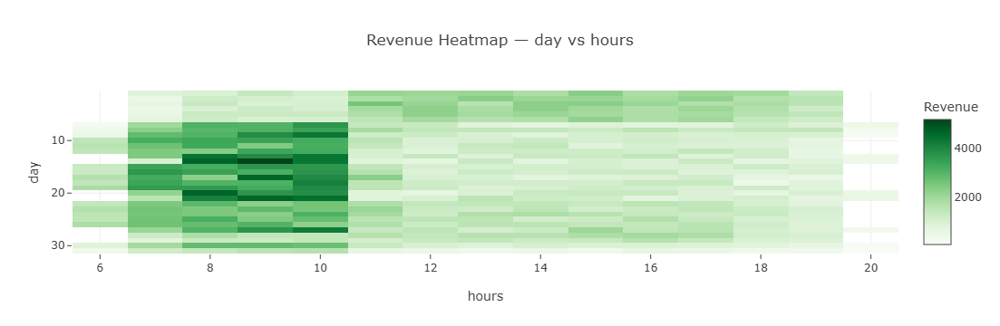

In [48]:
heatmap_data = (
    df.groupby(["day", "hours"])["Revenue"]
    .sum()
    .reset_index()
)

heatmap_pivot = heatmap_data.pivot(
    index="day",
    columns="hours",
    values="Revenue"
)

fig6 = px.imshow(
    heatmap_pivot,
    title="Revenue Heatmap — day vs hours",
    labels={
        "x": "hours",
        "y": "day",
        "color": "Revenue"
    },
    aspect="auto",color_continuous_scale="greens"

)

fig6.show()

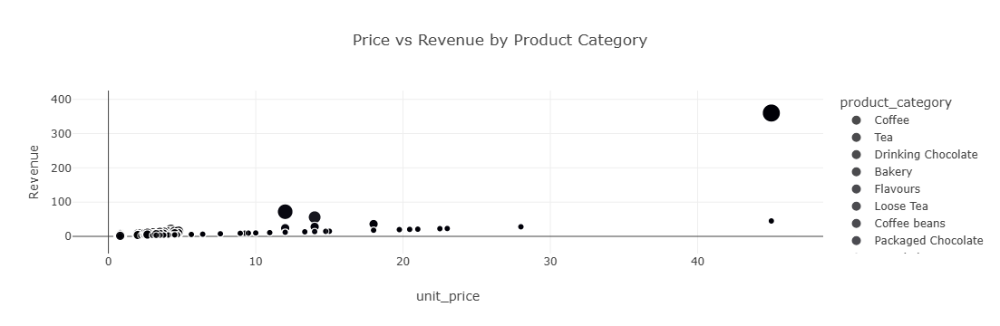

In [49]:
fig = px.scatter(
    df,
    x="unit_price",
    y="Revenue",
    size="transaction_qty",
    color="product_category",
    hover_data=[
        "product_detail",
        "store_location"
    ],
    title="Price vs Revenue by Product Category"
)

fig.show()

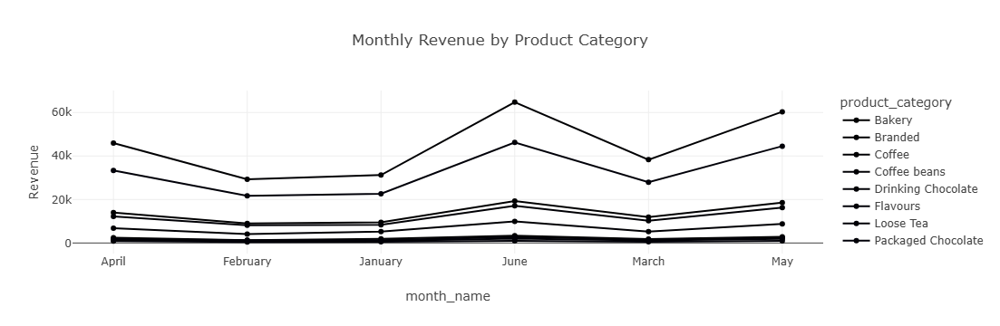

In [50]:
monthly_category = (
    df.groupby(
        ["month_name", "product_category"],
        as_index=False
    )["Revenue"]
    .sum()
)

fig = px.line(
    monthly_category,
    x="month_name",
    y="Revenue",
    color="product_category",
    markers=True,
    title="Monthly Revenue by Product Category"
)

fig.show()

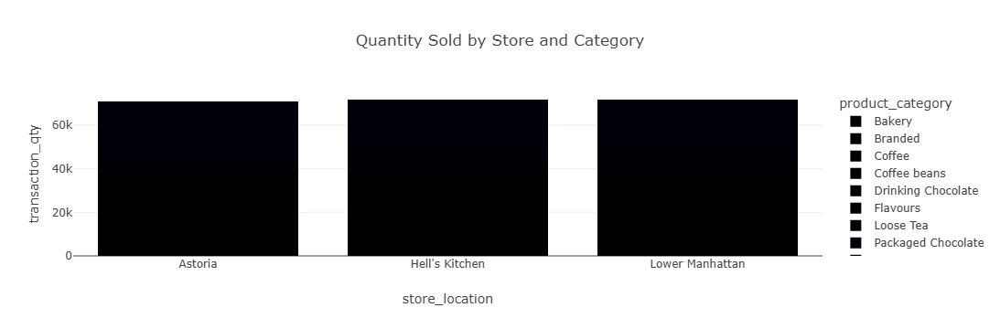

In [62]:
store_category_qty = (df.groupby(["store_location", "product_category"],as_index=False)["transaction_qty"].sum())
fig7 = px.bar(store_category_qty,x="store_location",y="transaction_qty",color="product_category",
                  title="Quantity Sold by Store and Category",barmode="stack")
fig7.show()

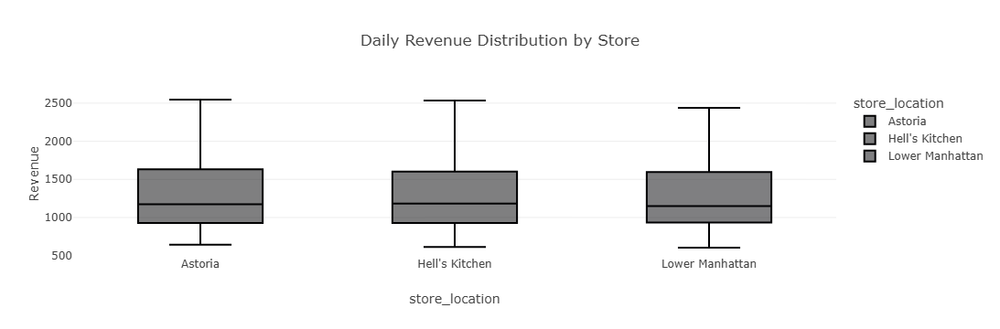

In [64]:
daily_store = (df.groupby(["transaction_date", "store_location"],as_index=False)["Revenue"].sum())
fig8 = px.box(daily_store,x="store_location",y="Revenue",color="store_location",title="Daily Revenue Distribution by Store")
fig8.show()

In [51]:
import os
os.getcwd()

'C:\\Users\\moh'

In [52]:
os.chdir(r'C:\Users\moh\Desktop\python project')

In [53]:
df.to_csv('project coffee shop Cleaned.csv')

 # Deployment

In [61]:
%%writefile project_coffee_shop.py
import pandas as pd
import numpy as np
import plotly.express as px
import streamlit as st

st.set_page_config(page_title='Coffee Shop Sales Analysis',layout='wide')

df=pd.read_csv('project coffee shop Cleaned.csv',index_col=0)

st.title('📊Coffee Shope Sales Analysis📊')
st.markdown('Project Data Analysis – Conducted and overseen by Dr. Mohamed Fathalla',width=500)
st.markdown('-------')
st.image('images.jfif',width=600)
tab1,tab2,tab3,tab4=st.tabs(['Data Overview','Univariate Analysis','Bivariate Analysis','Multivariate Analysis'])

with tab1:
    st.subheader('Dataset Preview')
    st.dataframe(df.head(10),hide_index=True,use_container_width=True)

    col1,col2,col3,col4 = st.columns(4)
    with col1:
        st.metric('Total Revenues',df['Revenue'] .sum().round(2))
    with col2:
        st.metric('Total Sales Units',df['transaction_qty'].sum())
    with col3:
        st.metric('Total Transaction',df['transaction_id'].nunique())
    with col4:
        st.metric('Average Order Value',df['Revenue'].mean().round(2))

with tab2:
    st.subheader('Univariate Analysis')
    st.markdown('select any column to view its details ',width=500)
    selected_column = st.selectbox('choose column:',df.columns)
    fig_uni = px.histogram(df,x=selected_column,title=f'Details of {selected_column}',color_discrete_sequence=['#653EFA'])
    st.plotly_chart(fig_uni,use_container_width=True)

    hour_count = df["hours"].value_counts().sort_index().reset_index()

    fig_1 = px.bar(hour_count,x="hours",y="count",title="Number of Transactions by Hour⏰",labels={"hours": "Hour of Day","count": "Transactions"})

    st.plotly_chart(fig_1,use_container_width=True)

    category_count = df["product_category"].value_counts().reset_index()

    fig_2 = px.pie(category_count,names="product_category",values="count",title="Transaction Distribution by Product Category")

    st.plotly_chart(fig_2,use_container_width=True)

    category_count = df["product_category"].value_counts().reset_index()

    fig_3 = px.bar(category_count,x="product_category",y="count",title="Number of Transactions by Product Category",
                   labels={"product_category": "Product Category","count": "Number of Transactions"})

    st.plotly_chart(fig_3,use_container_width=True)

with tab3:
    st.subheader('Bivariate Analysis')

    daily_sales = (df.groupby("transaction_date", as_index=False)["Revenue"].sum())

    fig2 = px.line(daily_sales,x="transaction_date",y="Revenue",title="Daily Revenue Trend",markers=True,color_discrete_sequence=['red'])

    st.plotly_chart(fig2,use_container_width=True)
    
    col1,col2 = st.columns(2)
    
    with col1:
        store_sales = (df.groupby("store_location", as_index=False)["Revenue"].sum().sort_values("Revenue", ascending=False))
        fig3 = px.bar(store_sales,x="store_location",y="Revenue",title="Revenue by Store",text_auto=".2s",color_discrete_sequence=['blue'])
        st.plotly_chart(fig3,use_container_width=True)
    
    with col2:
        hourly_sales = (df.groupby("hours", as_index=False)["Revenue"].sum())
        fig4 = px.bar(hourly_sales,x="hours",y="Revenue",title="Revenue by hours",color_discrete_sequence=['blue'])
        st.plotly_chart(fig4,use_container_width=True)

    top_products = (df.groupby("product_detail", as_index=False)["Revenue"].sum().sort_values("Revenue", ascending=False).head(10))
    fig5 = px.bar(top_products.sort_values("Revenue"),x="Revenue",y="product_detail",orientation="h",title="Top 10 Products by Revenue",
    text_auto=".2s",color_discrete_sequence=['green'])
    st.plotly_chart(fig5,use_container_width=True)

with tab4:
    st.subheader('Multivariate Analysis')
    monthly_category = (df.groupby(["month_name", "product_category"],as_index=False)["Revenue"].sum())
    fig6 = px.line(monthly_category,x="month_name",y="Revenue",color="product_category",markers=True,
                   title="Monthly Revenue by Product Category")
    st.plotly_chart(fig6,use_container_width=True)

    store_category_qty = (df.groupby(["store_location", "product_category"],as_index=False)["transaction_qty"].sum())
    fig7 = px.bar(store_category_qty,x="store_location",y="transaction_qty",color="product_category",
                  title="Quantity Sold by Store and Category",barmode="stack")

    st.plotly_chart(fig7,use_container_width=True)

    daily_store = (df.groupby(["transaction_date", "store_location"],as_index=False)["Revenue"].sum())
    fig8 = px.box(daily_store,x="store_location",y="Revenue",color="store_location",title="Daily Revenue Distribution by Store")

    st.plotly_chart(fig8,use_container_width=True)

    heatmap_data = (df.groupby(["day", "hours"])["Revenue"].sum().reset_index())
    
    heatmap_pivot = heatmap_data.pivot(index="day",columns="hours",values="Revenue")
    fig9 = px.imshow(heatmap_pivot,title="Revenue Heatmap — day vs hours",labels={
        "x": "hours",
        "y": "day",
        "color": "Revenue"},aspect="auto",color_continuous_scale="greens")

    st.plotly_chart(fig9,use_container_width=True)

    
       

    

    
    


Overwriting project_coffee_shop.py


In [55]:
! streamlit run project_coffee_shop.py

^C


In [69]:
! pip install pipreqs

In [75]:
!pipreqs ./ --encoding=utf-8 --force

Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
Please, verify manually the final list of requirements.txt to avoid possible dependency confusions.
INFO: Successfully saved requirements file in ./requirements.txt
